# Probabilistic SMS Spam Detection
### BAMAT207 – Probability and Statistics | Project Activity

**Name:** Kavin Raj SK &nbsp;|&nbsp; **Reg. No.:** 25BCE2866 &nbsp;|&nbsp; **Programme:** B.Tech, CSE – Core

**Question this notebook answers:** *Given only the words in a short text message, how confidently can probability tell a genuine message (ham) from unwanted spam?*

**Road map (mapped to the activity sheet)**

| Step | Activity | What happens here |
|---|---|---|
| 1–2 | Dataset handling & analysis | Load UCI SMS Spam Collection, clean it, compute P(Spam) and P(Ham), draw the class chart |
| 3 | Word-based probability | P(Spam \| Word) for *free, prize, win, urgent, offer* + Bayes' theorem check for *free* |
| 4 | Random variable | Y ∈ {0,1}, E(Y), Var(Y) |
| 5–6 | Preparation & model | Stratified 80:20 split, `CountVectorizer`, `MultinomialNB` |
| 7 | Evaluation | Accuracy, precision, recall, F1, confusion matrix, error inspection |
| 8 | Real-time testing | Type/paste a new SMS → prediction + P(Spam \| Message), P(Ham \| Message) |

> **Reproducibility note:** `RANDOM_STATE = 2866` — the last four digits of my registration number. Fixing the seed means anyone who runs this notebook top-to-bottom gets exactly my split and my numbers.

## Step 0 — Libraries
Run the install line only if a package is missing (Google Colab already has most of them).

In [1]:
# %pip install -q ucimlrepo pandas numpy matplotlib scikit-learn

import io, re, urllib.request, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

RANDOM_STATE = 2866   # last four digits of Reg. No. 25BCE2866
TEST_SIZE = 0.20
TARGET_WORDS = ["free", "prize", "win", "urgent", "offer"]
pd.set_option("display.width", 120)
print("Libraries ready.")

Libraries ready.


## Step 1 — Load the dataset (Activity 1)
Source: **UCI SMS Spam Collection (ID 228)** — 5,574 labelled SMS messages. The loader first tries `ucimlrepo`; if that route is unavailable it downloads/reads the official UCI ZIP, so the notebook works online, offline and in Colab.

In [2]:
def read_uci_zip(path_or_bytes):
    if isinstance(path_or_bytes, (bytes, bytearray)):
        archive = zipfile.ZipFile(io.BytesIO(path_or_bytes))
    else:
        archive = zipfile.ZipFile(path_or_bytes)
    member = next(n for n in archive.namelist() if n.endswith("SMSSpamCollection"))
    return pd.read_csv(io.BytesIO(archive.read(member)), sep="\t", header=None,
                       names=["label", "message"], quoting=3, encoding="utf-8")

def load_sms():
    try:
        from ucimlrepo import fetch_ucirepo
        fetched = fetch_ucirepo(id=228)
        frame = pd.concat([fetched.data.features, fetched.data.targets], axis=1)
        label_col = next(c for c in frame.columns
                         if set(frame[c].astype(str).str.lower().unique()) == {"ham", "spam"})
        text_col = next(c for c in frame.columns if c != label_col)
        data = frame[[label_col, text_col]].copy()
        data.columns = ["label", "message"]
        return data, "UCI API via ucimlrepo"
    except Exception as e:
        print("UCI API route unavailable ->", e)
    for p in [Path("data/sms+spam+collection.zip"), Path("sms+spam+collection.zip"),
              Path("/content/sms+spam+collection.zip")]:
        if p.exists():
            return read_uci_zip(p), f"local ZIP ({p})"
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    return read_uci_zip(urllib.request.urlopen(url).read()), "downloaded UCI ZIP"

raw, source = load_sms()
print("Loaded from:", source)
print("Raw shape:", raw.shape)
raw.head()

UCI API route unavailable -> "SMS Spam Collection" dataset (id=228) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true
Loaded from: local ZIP (data/sms+spam+collection.zip)
Raw shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Inspect before cleaning — missing values and raw class counts

In [3]:
print("Missing values per column:")
print(raw.isna().sum())
print("\nRaw label counts:")
print(raw["label"].astype(str).str.strip().str.lower().value_counts())

Missing values per column:
label      0
message    0
dtype: int64

Raw label counts:
label
ham     4827
spam     747
Name: count, dtype: int64


### Clean, de-duplicate and encode
Trim whitespace → keep only `ham`/`spam` → drop empty texts → **remove duplicate messages** → encode **Spam = 1, Ham = 0**. Removing duplicates *before* splitting also stops the same text appearing in both train and test sets.

In [4]:
data = raw.copy()
data["label"] = data["label"].astype(str).str.strip().str.lower()
data["message"] = data["message"].astype(str).str.strip()
data = data[data["label"].isin(["ham", "spam"])]
data = data[data["message"] != ""]
data = data.drop_duplicates(subset=["message"], keep="first").reset_index(drop=True)
data["label_encoded"] = data["label"].map({"ham": 0, "spam": 1}).astype(int)

print(f"Raw rows: {len(raw):,}  ->  Cleaned rows: {len(data):,}  "
      f"(duplicates removed: {len(raw) - len(data):,})")
print("Duplicates remaining:", int(data.duplicated(subset=['message']).sum()))
data["label"].value_counts()

Raw rows: 5,574  ->  Cleaned rows: 5,160  (duplicates removed: 414)
Duplicates remaining: 0


label
ham     4518
spam     642
Name: count, dtype: int64

## Step 2 — Class distribution and prior probabilities (Activity 2)
$$P(Spam)=\frac{\text{spam messages}}{\text{total messages}}\qquad P(Ham)=\frac{\text{ham messages}}{\text{total messages}}$$

N = 5,160
P(Ham)  = 4518/5160 = 0.8755814  (87.56%)
P(Spam) = 642/5160 = 0.1244186  (12.44%)
Check: P(Ham) + P(Spam) = 1.0000000


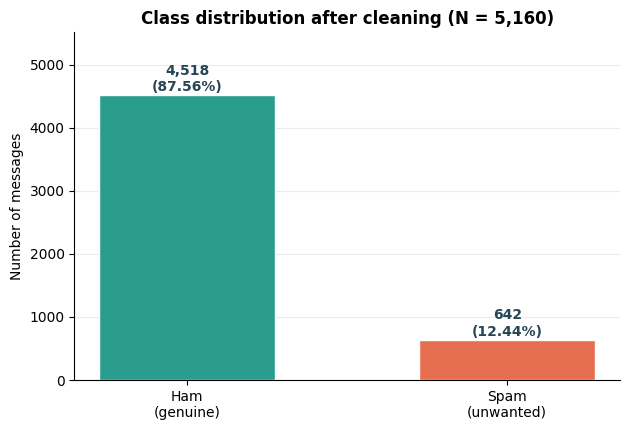

In [5]:
counts = data["label"].value_counts().reindex(["ham", "spam"])
N = len(data)
p_ham, p_spam = counts["ham"] / N, counts["spam"] / N
print(f"N = {N:,}")
print(f"P(Ham)  = {counts['ham']}/{N} = {p_ham:.7f}  ({p_ham:.2%})")
print(f"P(Spam) = {counts['spam']}/{N} = {p_spam:.7f}  ({p_spam:.2%})")
print(f"Check: P(Ham) + P(Spam) = {p_ham + p_spam:.7f}")

fig, ax = plt.subplots(figsize=(6.4, 4.4))
bars = ax.bar(["Ham\n(genuine)", "Spam\n(unwanted)"], [counts["ham"], counts["spam"]],
              color=["#2A9D8F", "#E76F51"], edgecolor="white", width=0.55)
for bar, lab in zip(bars, ["ham", "spam"]):
    v = int(counts[lab])
    ax.text(bar.get_x() + bar.get_width()/2, v + N*0.012, f"{v:,}\n({v/N:.2%})",
            ha="center", fontweight="bold", color="#264653")
ax.set_ylim(0, counts.max()*1.22); ax.set_ylabel("Number of messages")
ax.set_title(f"Class distribution after cleaning (N = {N:,})", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.yaxis.grid(alpha=0.25); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### A quick extra look: are spam messages longer?
*(My own addition — length is not used by the classifier, but it shows the two classes behave differently even before any modelling.)*

char_length                 word_count                
             mean median min  max       mean median min  max
label                                                       
ham         70.86   53.0   2  910      14.23   11.0   1  171
spam       137.41  148.0  13  223      23.70   25.0   2   35

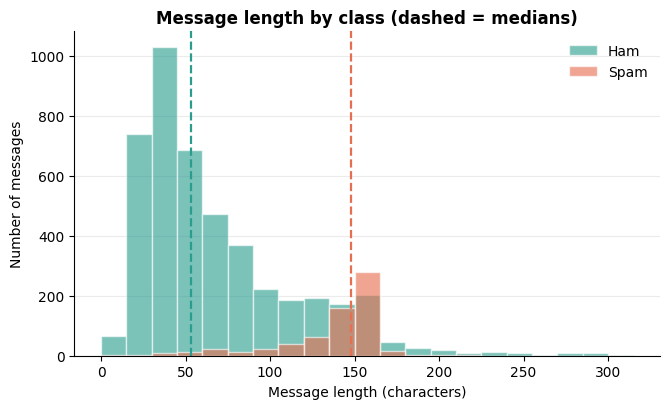

Reading: the median spam text is far longer than the median ham text - promotional copy needs room for the pitch, the prize and the call to action.


In [6]:
data["char_length"] = data["message"].str.len()
data["word_count"] = data["message"].str.split().str.len()
display(data.groupby("label")[["char_length", "word_count"]].agg(["mean", "median", "min", "max"]).round(2))

fig, ax = plt.subplots(figsize=(6.8, 4.2))
bins = np.arange(0, 325, 15)
for lab, colour in [("ham", "#2A9D8F"), ("spam", "#E76F51")]:
    s = data.loc[data["label"] == lab, "char_length"].clip(upper=320)
    ax.hist(s, bins=bins, alpha=0.62, color=colour, label=lab.capitalize(), edgecolor="white")
    ax.axvline(s.median(), color=colour, linestyle="--", linewidth=1.6)
ax.set_xlabel("Message length (characters)"); ax.set_ylabel("Number of messages")
ax.set_title("Message length by class (dashed = medians)", fontweight="bold"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); ax.yaxis.grid(alpha=0.25); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
print("Reading: the median spam text is far longer than the median ham text - "
      "promotional copy needs room for the pitch, the prize and the call to action.")

## Step 3 — Word-based conditional probability (Activity 3)
Counting rule: a message *contains* a word if the **whole word** occurs at least once, ignoring case (`FREE` = `free`, but `freedom` ≠ `free`). Repeats inside one message still count once.

$$P(Spam\mid Word)=\frac{\text{spam messages containing the word}}{\text{all messages containing the word}}$$

I also report **lift** = P(Spam | Word) ÷ P(Spam): how many times more likely spam becomes once the word is seen.

In [7]:
def word_table(words):
    n_spam, n_ham = int(counts["spam"]), int(counts["ham"])
    rows = []
    for w in words:
        has = data["message"].str.contains(rf"\b{re.escape(w)}\b", case=False, regex=True)
        total_w, spam_w = int(has.sum()), int((has & (data["label"] == "spam")).sum())
        ham_w = total_w - spam_w
        rows.append({"Word": w, "Messages with word": total_w, "Spam": spam_w, "Ham": ham_w,
                     "P(Word)": total_w / N, "P(Word | Spam)": spam_w / n_spam,
                     "P(Word | Ham)": ham_w / n_ham,
                     "P(Spam | Word)": spam_w / total_w, "P(Ham | Word)": ham_w / total_w,
                     "Lift over prior": (spam_w / total_w) / p_spam})
    return pd.DataFrame(rows)

word_df = word_table(TARGET_WORDS)
word_df.style.format({c: "{:.4f}" for c in word_df.columns if c.startswith("P(") or c.startswith("Lift")})

,Word,Messages with word,Spam,Ham,P(Word),P(Word | Spam),P(Word | Ham),P(Spam | Word),P(Ham | Word),Lift over prior
0,free,199,144,55,0.0386,0.2243,0.0122,0.7236,0.2764,5.8160
1,prize,70,70,0,0.0136,0.1090,0.0000,1.0000,0.0000,8.0374
2,win,53,47,6,0.0103,0.0732,0.0013,0.8868,0.1132,7.1275
3,urgent,61,56,5,0.0118,0.0872,0.0011,0.9180,0.0820,7.3786
4,offer,30,24,6,0.0058,0.0374,0.0013,0.8000,0.2000,6.4299


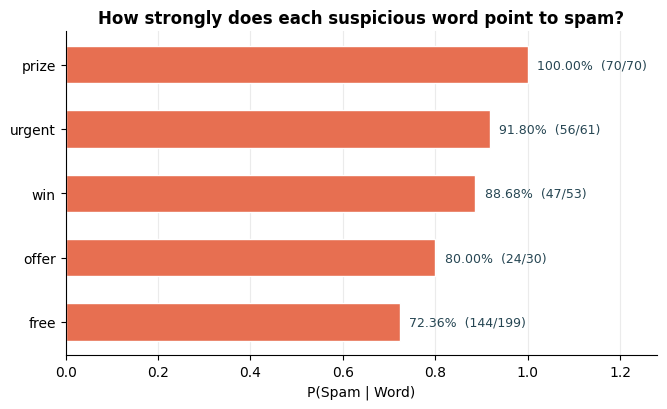

Bonus check (common words are far weaker signals):


,Word,Messages with word,Spam,Ham,P(Word),P(Word | Spam),P(Word | Ham),P(Spam | Word),P(Ham | Word),Lift over prior
0,claim,91,91,0,0.017636,0.141745,0.000000,1.000000,0.000000,8.037383
1,call,454,277,177,0.087984,0.431464,0.039177,0.610132,0.389868,4.903866
2,text,157,92,65,0.030426,0.143302,0.014387,0.585987,0.414013,4.709804


In [8]:
ordered = word_df.sort_values("P(Spam | Word)")
fig, ax = plt.subplots(figsize=(6.8, 4.2))
bars = ax.barh(ordered["Word"], ordered["P(Spam | Word)"], color="#E76F51", edgecolor="white", height=0.58)
for bar, (_, r) in zip(bars, ordered.iterrows()):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
            f"{r['P(Spam | Word)']:.2%}  ({int(r['Spam'])}/{int(r['Messages with word'])})",
            va="center", fontsize=9, color="#264653")
ax.set_xlim(0, 1.28); ax.set_xlabel("P(Spam | Word)")
ax.set_title("How strongly does each suspicious word point to spam?", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.xaxis.grid(alpha=0.25); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

# My own extension: everyday words, for contrast
print("Bonus check (common words are far weaker signals):")
display(word_table(["claim", "call", "text"]))

### Bayes' theorem — an independent route to P(Spam | Free)
$$P(Spam\mid Free)=\frac{P(Free\mid Spam)\;\times\;P(Spam)}{P(Free)}$$

In [9]:
free = word_df.loc[word_df["Word"] == "free"].iloc[0]
p_free_given_spam = free["P(Word | Spam)"]
p_free = free["P(Word)"]
bayes = (p_free_given_spam * p_spam) / p_free
direct = free["Spam"] / free["Messages with word"]

print(f"Step 1  P(Free | Spam) = {int(free['Spam'])}/{int(counts['spam'])} = {p_free_given_spam:.7f}")
print(f"Step 2  x P(Spam)      = {p_spam:.7f}   -> numerator = {p_free_given_spam * p_spam:.7f}")
print(f"Step 3  / P(Free)      = {p_free:.7f}")
print(f"Bayes        P(Spam | Free) = {bayes:.7f}")
print(f"Direct count P(Spam | Free) = {int(free['Spam'])}/{int(free['Messages with word'])} = {direct:.7f}")
print("Match:", np.isclose(bayes, direct), "- the theorem and the raw count agree.")

Step 1  P(Free | Spam) = 144/642 = 0.2242991
Step 2  x P(Spam)      = 0.1244186   -> numerator = 0.0279070
Step 3  / P(Free)      = 0.0385659
Bayes        P(Spam | Free) = 0.7236181
Direct count P(Spam | Free) = 144/199 = 0.7236181
Match: True - the theorem and the raw count agree.


## Step 4 — The label as a random variable (Activity 4)
$Y = 1$ for spam, $Y = 0$ for ham → $Y$ is Bernoulli with $p = P(Spam)$, so $E(Y)=p$ and $Var(Y)=p(1-p)$.

In [10]:
y_all = data["label_encoded"].to_numpy(dtype=float)
E_Y = float(np.mean(y_all))
Var_Y = float(np.var(y_all, ddof=0))   # population variance of the observed corpus
print(f"E(Y)   = mean(Y) = {E_Y:.7f}      (= P(Spam) = {p_spam:.7f})")
print(f"Var(Y) = p(1-p)  = {E_Y * (1 - E_Y):.7f}")
print(f"NumPy population variance check = {Var_Y:.7f}")
print(f"SD(Y)  = {np.sqrt(Var_Y):.7f}")
print("\nIn plain words: pick one cleaned message at random and the expected value of its")
print("spam indicator is 0.1244 - i.e. about 1 message in 8 is spam in this corpus.")

E(Y)   = mean(Y) = 0.1244186      (= P(Spam) = 0.1244186)
Var(Y) = p(1-p)  = 0.1089386
NumPy population variance check = 0.1089386
SD(Y)  = 0.3300585

In plain words: pick one cleaned message at random and the expected value of its
spam indicator is 0.1244 - i.e. about 1 message in 8 is spam in this corpus.


## Steps 5–6 — Split, vectorize and train Multinomial Naive Bayes (Activities 5–6)
- **80:20 stratified split** keeps the 87.56 : 12.44 ham–spam ratio in both parts.
- `CountVectorizer` is fitted on **training text only** (`fit_transform` on train, `transform` on test) — fitting it on everything would leak test vocabulary into training.

In [11]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    data["message"], data["label_encoded"],
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=data["label_encoded"])

vectorizer = CountVectorizer(lowercase=True)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

model = MultinomialNB()
model.fit(X_train, y_train)

print(f"Train: {len(X_train_text):,}  (ham {(y_train==0).sum():,}, spam {(y_train==1).sum():,})")
print(f"Test : {len(X_test_text):,}  (ham {(y_test==0).sum():,}, spam {(y_test==1).sum():,})")
print(f"Vocabulary size (train only): {len(vectorizer.get_feature_names_out()):,} tokens")
print(f"Feature matrix: train {X_train.shape}, test {X_test.shape} (sparse word counts)")

Train: 4,128  (ham 3,614, spam 514)
Test : 1,032  (ham 904, spam 128)
Vocabulary size (train only): 7,597 tokens
Feature matrix: train (4128, 7597), test (1032, 7597) (sparse word counts)


## Step 7 — Evaluation (Activity 7)
Accuracy alone flatters a model on imbalanced data (always answering "ham" would already score ~87.6%), so spam **precision** (of the messages flagged, how many really are spam?) and **recall** (of all real spam, how much did we catch?) matter just as much.

In [12]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1)
rec = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
TN, FP, FN, TP = int(cm[0,0]), int(cm[0,1]), int(cm[1,0]), int(cm[1,1])

print(f"Accuracy       = ({TP}+{TN})/{TP+TN+FP+FN} = {acc:.6f} ({acc:.2%})")
print(f"Spam precision = {TP}/({TP}+{FP}) = {prec:.6f} ({prec:.2%})")
print(f"Spam recall    = {TP}/({TP}+{FN}) = {rec:.6f} ({rec:.2%})")
print(f"Spam F1-score  = {f1:.6f} ({f1:.2%})")
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, labels=[0,1], target_names=["Ham (0)", "Spam (1)"], digits=4))

Accuracy       = (118+902)/1032 = 0.988372 (98.84%)
Spam precision = 118/(118+2) = 0.983333 (98.33%)
Spam recall    = 118/(118+10) = 0.921875 (92.19%)
Spam F1-score  = 0.951613 (95.16%)

Classification report:

              precision    recall  f1-score   support

     Ham (0)     0.9890    0.9978    0.9934       904
    Spam (1)     0.9833    0.9219    0.9516       128

    accuracy                         0.9884      1032
   macro avg     0.9862    0.9598    0.9725      1032
weighted avg     0.9883    0.9884    0.9882      1032



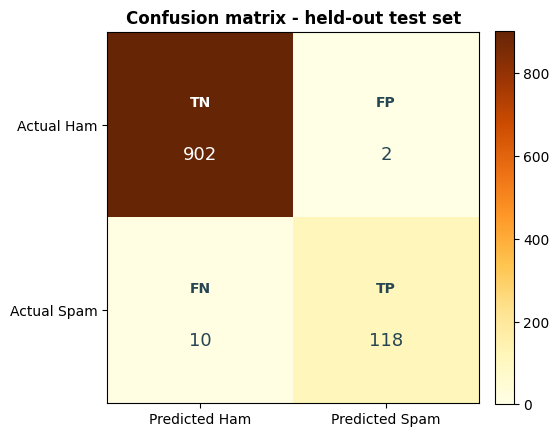

Spam wrongly passed as genuine (FN): 10   |   Genuine wrongly flagged as spam (FP): 2


In [13]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
img = ax.imshow(cm, cmap="YlOrBr", vmin=0)
ax.set_xticks([0,1], labels=["Predicted Ham", "Predicted Spam"])
ax.set_yticks([0,1], labels=["Actual Ham", "Actual Spam"])
tags = [["TN", "FP"], ["FN", "TP"]]
for (r, c), v in np.ndenumerate(cm):
    colour = "white" if v > cm.max()*0.55 else "#264653"
    ax.text(c, r-0.12, tags[r][c], ha="center", va="center", color=colour, fontweight="bold")
    ax.text(c, r+0.16, f"{int(v):,}", ha="center", va="center", color=colour, fontsize=13)
ax.set_title("Confusion matrix - held-out test set", fontweight="bold")
fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()
print(f"Spam wrongly passed as genuine (FN): {FN}   |   Genuine wrongly flagged as spam (FP): {FP}")

### Look at the mistakes — they explain *why* the model is not perfect

In [14]:
probs = model.predict_proba(X_test)
ham_c, spam_c = list(model.classes_).index(0), list(model.classes_).index(1)
errors = pd.DataFrame({"message": X_test_text.to_numpy(), "actual": y_test.to_numpy(),
                       "predicted": y_pred, "P(Ham)": probs[:, ham_c], "P(Spam)": probs[:, spam_c]})
print("FALSE NEGATIVES - spam the model let through (first 5):")
display(errors[(errors.actual == 1) & (errors.predicted == 0)].head(5))
print("FALSE POSITIVES - genuine messages flagged as spam:")
display(errors[(errors.actual == 0) & (errors.predicted == 1)])
print("Pattern: missed spam reads like personal chat or a service note and avoids the classic")
print("prize/free vocabulary; the false alarms are short job/service texts with formal wording.")

FALSE NEGATIVES - spam the model let through (first 5):


,message,actual,predicted,P(Ham),P(Spam)
169,Not heard from U4 a while. Call me now am here...,1,0,1.000000,4.767778e-11
224,Ever thought about living a good life with a p...,1,0,0.871043,1.289574e-01
250,LookAtMe!: Thanks for your purchase of a video...,1,0,0.999076,9.236441e-04
291,Guess who am I?This is the first time I create...,1,0,0.950971,4.902920e-02
298,Your next amazing xxx PICSFREE1 video will be ...,1,0,0.989854,1.014595e-02


FALSE POSITIVES - genuine messages flagged as spam:


,message,actual,predicted,P(Ham),P(Spam)
776,We have sent JD for Customer Service cum Accou...,0,1,0.133267,0.866733
779,Waiting for your call.,0,1,0.411531,0.588469


Pattern: missed spam reads like personal chat or a service note and avoids the classic
prize/free vocabulary; the false alarms are short job/service texts with formal wording.


## Step 8 — Real-time SMS testing (Activity 8)
A new message must go through the **same fitted vectorizer** (`transform`, never a fresh `fit`) so it lands in the feature space the model learned.

In [15]:
def predict_sms(message):
    features = vectorizer.transform([message])
    p = model.predict_proba(features)[0]
    by_class = {int(c): float(v) for c, v in zip(model.classes_, p)}
    label = "Spam" if int(model.predict(features)[0]) == 1 else "Ham (genuine)"
    print(f"SMS: {message}")
    print(f"Prediction: {label}")
    print(f"P(Spam | Message) = {by_class[1]:.9f}")
    print(f"P(Ham | Message)  = {by_class[0]:.9f}\n")
    return label, by_class[1], by_class[0]

# 1) the exact example from the activity sheet
predict_sms("Congratulations! You have won a free prize. Claim now.")

# 2) my own extra tests
for msg in ["URGENT! Your account will be blocked. Verify your details now to claim your offer.",
            "Hi, are we still meeting for lunch tomorrow at 1?",
            "Your OTP is 482913. Please do not share it with anyone.",
            "WINNER! You have been selected for a free holiday. Call now to claim your prize!"]:
    predict_sms(msg)

SMS: Congratulations! You have won a free prize. Claim now.
Prediction: Spam
P(Spam | Message) = 0.999999641
P(Ham | Message)  = 0.000000359

SMS: URGENT! Your account will be blocked. Verify your details now to claim your offer.
Prediction: Spam
P(Spam | Message) = 0.999995942
P(Ham | Message)  = 0.000004058

SMS: Hi, are we still meeting for lunch tomorrow at 1?
Prediction: Ham (genuine)
P(Spam | Message) = 0.000001574
P(Ham | Message)  = 0.999998426

SMS: Your OTP is 482913. Please do not share it with anyone.
Prediction: Ham (genuine)
P(Spam | Message) = 0.000203184
P(Ham | Message)  = 0.999796816

SMS: WINNER! You have been selected for a free holiday. Call now to claim your prize!
Prediction: Spam
P(Spam | Message) = 0.999999998
P(Ham | Message)  = 0.000000002



In [16]:
# ---- TRY YOUR OWN MESSAGE: edit the text below and re-run this cell ----
my_message = "You have won a free gift card! Click the link to claim your prize now."
predict_sms(my_message)

# Optional typed loop (works in a local notebook; in Colab use the cell above):
# while True:
#     text = input("Enter an SMS message (or 'exit'): ")
#     if text.strip().lower() in {"exit", "quit"}: break
#     if text.strip(): predict_sms(text)

SMS: You have won a free gift card! Click the link to claim your prize now.
Prediction: Spam
P(Spam | Message) = 0.999999933
P(Ham | Message)  = 0.000000067



('Spam', 0.9999999334154972, 6.658450967886928e-08)

## Conclusion
- In the cleaned corpus (5,160 unique messages) spam is the minority class: **P(Spam) = 0.1244, P(Ham) = 0.8756**, hence **E(Y) = 0.1244** and **Var(Y) = 0.1089**.
- Single words already carry strong evidence — seeing *prize*, *urgent* or *win* lifts the spam probability to **89–100%** in this dataset — and Bayes' theorem reproduces the counted **P(Spam | Free) = 0.7236** exactly.
- Multinomial Naive Bayes generalises the same idea to thousands of words at once and, on messages it had never seen, reached **98.84% accuracy** with spam **precision 98.33% / recall 92.19% / F1 95.16%** (confusion matrix [[902, 2], [10, 118]]).
- The remaining errors are instructive: spam disguised as ordinary conversation slips through, while a couple of formal service messages get flagged — exactly the boundary where a bag-of-words probability model should be expected to struggle.

**Files in this project:** this notebook • `sms_spam_detection.py` • project report (PDF/DOCX) • `data/cleaned_dataset.csv` • `figures/` • `outputs/` • trained model in `model/`.

*— Kavin Raj SK, 25BCE2866*